In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [10]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate, validation_curve
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor, XGBClassifier

In [11]:
X_train_df = pd.read_csv('../../03.results/outputs/X_train.csv')
y_train_df = pd.read_csv('../../03.results/outputs/y_train.csv')

In [12]:
X_train_df.head()

,Unnamed: 0,last_return,return_3d,returnvola_3d,return_7d,returnvola_7d,return_14d,returnvola_14d,return_21d,returnvola_21d,...,vol_ratio_30,log_vol_change,ret_lag1,ret_lag2,ret_lag3,dow_sin,dow_cos,month_sin,month_cos,is_weekend
0,3,-0.003773,0.026712,0.016243,0.370262,0.109590,0.487023,0.084580,0.551213,0.073999,...,0.759275,-0.800778,0.003292,0.027219,0.203704,-0.974928,-0.222521,-0.866025,-0.5,1
1,4,0.025687,0.025181,0.015381,0.180629,0.090677,0.591873,0.081936,0.634908,0.073093,...,0.907519,0.176624,-0.003773,0.003292,0.027219,-0.781831,0.623490,-0.866025,-0.5,1
2,5,-0.051373,-0.030676,0.038884,0.080453,0.095162,0.534008,0.084218,0.646420,0.072724,...,0.795709,-0.146771,0.025687,-0.003773,0.003292,0.000000,1.000000,-0.866025,-0.5,0
3,6,-0.014893,-0.041495,0.038548,0.184575,0.082292,0.451983,0.085189,0.551853,0.073129,...,0.841346,0.028988,-0.051373,0.025687,-0.003773,0.781831,0.623490,-0.866025,-0.5,0
4,7,-0.029376,-0.092952,0.018369,-0.044801,0.028527,0.363417,0.086642,0.555617,0.073043,...,0.831754,-0.007168,-0.014893,-0.051373,0.025687,0.974928,-0.222521,-0.866025,-0.5,0


In [13]:
y_train_df.head()

,Unnamed: 0,target_next_return,target_direction,target_next_close
0,3,0.025687,1,6.229
1,4,-0.051373,0,5.909
2,5,-0.014893,0,5.821
3,6,-0.029376,0,5.650
4,7,0.114513,1,6.297


In [14]:
y_reg = y_train_df["target_next_return"]
y_clf = y_train_df["target_direction"]

 Only X_train and y_train are loaded. The test files are intentionally untouched here.

In [17]:
cut = int(len(X_train_df) * 0.8)
Xa, Xb, ya, yb = X_train_df.iloc[:cut], X_train_df.iloc[cut:], y_clf.iloc[:cut], y_clf.iloc[cut:]

In [18]:
es = XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                   min_child_weight=5, eval_metric="logloss", early_stopping_rounds=40, n_jobs=1, random_state=42)

In [19]:
es.fit(Xa, ya, eval_set=[(Xa, ya), (Xb, yb)], verbose=False)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",40
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [20]:
hist = es.evals_result()
print(hist.keys())

dict_keys(['validation_0', 'validation_1'])


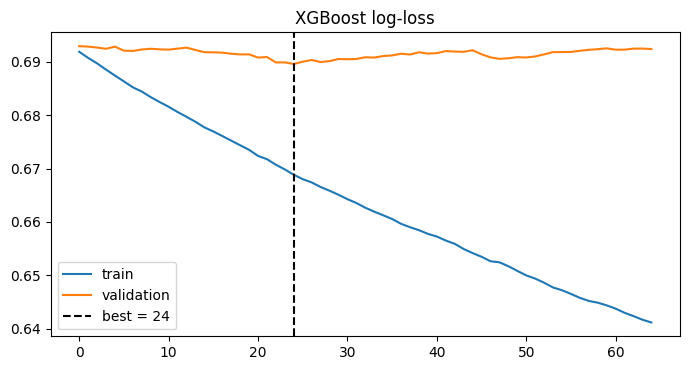

In [25]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(hist["validation_0"]["logloss"], label="train"); ax.plot(hist["validation_1"]["logloss"], label="validation")
ax.axvline(es.best_iteration, color="k", ls="--", label=f"best = {es.best_iteration}"); ax.legend(); ax.set_title("XGBoost log-loss")
plt.tight_layout(); fig.savefig("../../03.results/eda_visualizations/xgb_early_stopping.png", dpi=130); plt.show()

In [26]:
tscv = TimeSeriesSplit(n_splits=5)
REG_SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
CLF_SCORING = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}

def cv_scores(model, y, task):
    scoring = REG_SCORING if task == "regression" else CLF_SCORING
    res = cross_validate(model, X_train_df, y, cv=tscv, scoring=scoring, n_jobs=-1)
    out = {"task": task}
    for k in scoring:
        v = res[f"test_{k}"]
        v = -v if k in ("rmse", "mae") else v
        out[k] = v.mean(); out[k + "_std"] = v.std()
    return out


def plot_curve(model, y, param, values, scoring, title, fname, flip=False):
    tr, va = validation_curve(model, X_train_df, y, param_name=param, param_range=values, cv=tscv, scoring=scoring, n_jobs=-1)
    s = -1 if flip else 1
    xs = np.arange(len(values)); labels = [str(v) for v in values]
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for arr, name in ((s * tr, "train"), (s * va, "validation")):
        ax.plot(xs, arr.mean(1), marker="o", label=name)
        ax.fill_between(xs, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), alpha=0.15)
    ax.set_xticks(xs); ax.set_xticklabels(labels); ax.set_xlabel(param); ax.set_title(title); ax.legend()
    plt.tight_layout(); fig.savefig("../../03.results/eda_visualizations/" + fname, dpi=130); plt.show()
    return pd.DataFrame({"value": labels, "train": (s * tr).mean(1), "validation": (s * va).mean(1)})

In [27]:
reg = Pipeline([("model", XGBRegressor(n_estimators=100, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                                        min_child_weight=5, n_jobs=1, random_state=42))])

In [28]:
clf = Pipeline([("model", XGBClassifier(n_estimators=100, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                                         min_child_weight=5, eval_metric="logloss", n_jobs=1, random_state=42))])

In [29]:
r_reg = cv_scores(reg, y_reg, "regression"); r_clf = cv_scores(clf, y_clf, "classification")
print({k: round(v, 4) for k, v in r_reg.items() if k != "task"}); print({k: round(v, 4) for k, v in r_clf.items() if k != "task"})

{'rmse': np.float64(0.0516), 'rmse_std': np.float64(0.0168), 'mae': np.float64(0.0378), 'mae_std': np.float64(0.0121), 'r2': np.float64(-0.085), 'r2_std': np.float64(0.0723)}
{'accuracy': np.float64(0.5138), 'accuracy_std': np.float64(0.0238), 'f1': np.float64(0.5184), 'f1_std': np.float64(0.0946), 'roc_auc': np.float64(0.5168), 'roc_auc_std': np.float64(0.0267)}


Compare the numbers to ROC-AUC 0.5 and accuracy ~0.5 (classification) or the zero-return error (regression). Differences within one std are noise.

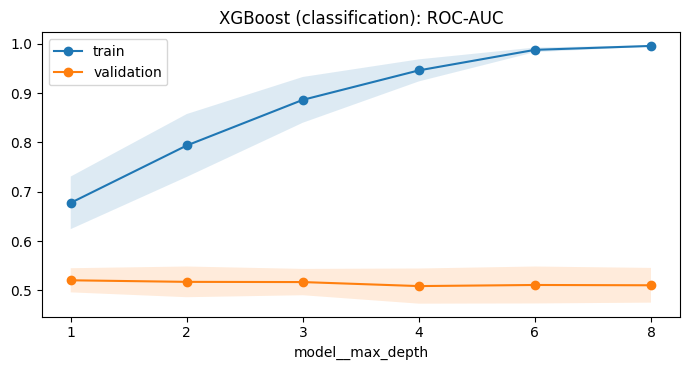

,value,train,validation
0,1,0.677,0.520
1,2,0.794,0.517
2,3,0.886,0.517
3,4,0.946,0.509
4,6,0.988,0.511
5,8,0.996,0.510


In [30]:
g = plot_curve(clf, y_clf, "model__max_depth", [1, 2, 3, 4, 6, 8], "roc_auc", "XGBoost (classification): ROC-AUC", "xgb_depth_clf.png")
g.round(3)

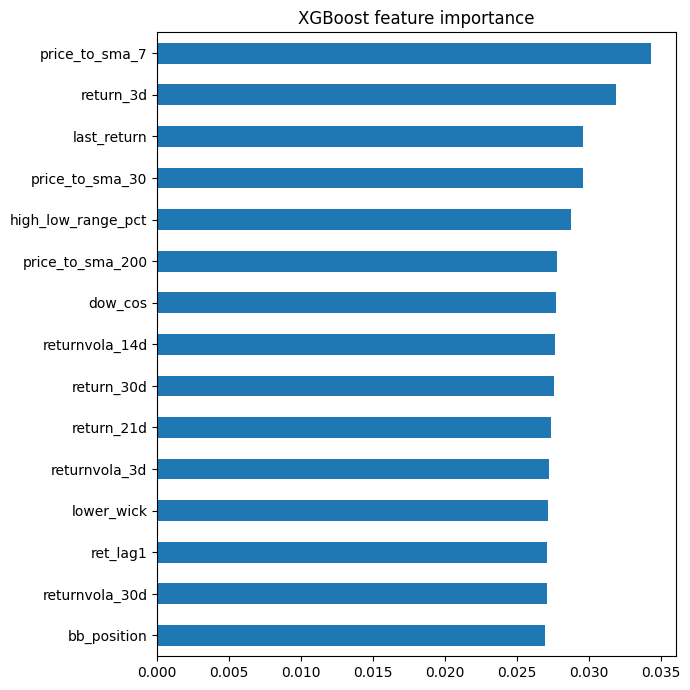

In [31]:
clf.fit(X_train_df, y_clf)
imp = pd.Series(clf.named_steps["model"].feature_importances_, index=X_train_df.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 7)); imp.tail(15).plot.barh(ax=ax); ax.set_title("XGBoost feature importance")
plt.tight_layout(); fig.savefig("../../03.results/eda_visualizations/xgb_importance.png", dpi=130); plt.show()

In [32]:
rows = [{"model": "XGBoost", **r_reg}, {"model": "XGBoost", **r_clf}]
res = pd.DataFrame(rows)
res.to_csv("../../03.results/outputs/model_results_xgboost.csv", index=False)
res.round(4)

,model,task,rmse,rmse_std,mae,mae_std,r2,r2_std,accuracy,accuracy_std,f1,f1_std,roc_auc,roc_auc_std
0,XGBoost,regression,0.0516,0.0168,0.0378,0.0121,-0.085,0.0723,NaN,NaN,NaN,NaN,NaN,NaN
1,XGBoost,classification,NaN,NaN,NaN,NaN,NaN,NaN,0.5138,0.0238,0.5184,0.0946,0.5168,0.0267
